## Embeddings: Proyección y clustering latente

- Se proyectan los embeddings a 2D con **UMAP** y se agrupan con **KMeans** en el espacio latente

- Se mide la **convergencia** con los clústeres de la Parte II, la centralidad de la Parte IV y las comunidades de la Parte V

- **Local** (umap-learn + scikit-learn): 57k × 64 cabe en memoria; UMAP no tiene versión en Spark

### Constantes

- `RANGO_VECINOS`: `n_neighbors` de UMAP (tamaño del vecindario que conserva)

- `MIN_DIST` = 0.1: separación mínima de puntos en 2D; valor por defecto, solo afecta la estética

- `N_UMAP` = 15,000: nodos al azar que se proyectan (el clustering usa **todos**)

- `RANGO_K`: número de grupos latentes que se prueban

- `N_WEB` = 5,000: nodos de la proyección que se exportan para la web

In [1]:
RANGO_VECINOS = [15, 30, 50]
MIN_DIST = 0.1
N_UMAP = 15000
RANGO_K = [4, 6, 8, 10, 12, 15, 20]
N_WEB = 5000

### Utilidades

In [2]:
NOTEBOOK = "c_proyeccion"
%run ../funciones.ipynb
%run funciones.ipynb
import umap
from sklearn.manifold import trustworthiness

Note: you may need to restart the kernel to use updated packages.


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

- Embeddings de la grilla y SVD de `b_node2vec`

- **Parte II:** tipología y etiquetas de KMeans, DBSCAN, HDBSCAN y Ward

- **Parte IV:** PageRank y HITS

- **Parte V:** comunidades Louvain del núcleo de co-participación (ver `COMUNIDADES` en `funciones`)

In [4]:
config = leer_config()
nodos = pd.read_parquet(datos_dir / "nodos.parquet")
n = len(nodos)
embs = {c: normalizar(np.load(datos_dir / f"emb_{c}.npy")) for c in config["configs"]}
nodos["tipologia"] = tipologia_proveedor(nodos.clave)
previas = particiones_previas(nodos.clave)
comunidades = cargar_comunidades(nodos.clave)
central = centralidad_previa(nodos.clave)
nodos["pct_pagerank"] = central.pagerank.rank(pct=True).to_numpy() if central is not None else np.nan
nodos["pct_hits"] = central.hits.rank(pct=True).to_numpy() if central is not None and "hits" in central else np.nan
cobertura = pd.DataFrame([("nodos", n)] + [(f"con {c}", int(previas[c].notna().sum())) for c in previas.columns[1:]] +
                         [("con PageRank (Parte IV)", int(nodos.pct_pagerank.notna().sum())),
                          ("con comunidad (Parte V)", 0 if comunidades is None else int(pd.notna(comunidades).sum()))],
                         columns=["medida", "valor"])
cobertura

Parte V disponible (louvain): 41 comunidades en 7,116 proveedores del núcleo


,medida,valor
0,nodos,56975
1,con kmeans,11665
2,con dbscan,11665
3,con hdbscan,11665
4,con jerarquico,4367
5,con PageRank (Parte IV),25677
6,con comunidad (Parte V),7116


- **11,665 de 56,975 nodos (20%) tienen tipología de la Parte II:** el clustering de la Parte II solo incluye ganadores con ≥ 3 procesos; la mayoría del grafo son postores

- **25,677 (45%) tienen PageRank/HITS de la Parte IV:** los que ganaron al menos una vez (nodos del bipartito)

- **7,116 (12%) tienen comunidad de la Parte V:** su núcleo exige ≥ 20 procesos compartidos por arista

- La convergencia con II, IV y V se mide sobre esos subconjuntos

---
### **1. Parámetros de UMAP**

- **Confiabilidad (trustworthiness):** qué tanto los vecinos en 2D son vecinos reales en el embedding (1 = perfecto)

- Se mide sobre una muestra de 3,000 nodos con p = q = 1

In [5]:
rng = np.random.default_rng(SEED)
m_umap = np.sort(rng.choice(n, N_UMAP, replace=False))
m_tw = rng.choice(N_UMAP, 3000, replace=False)
X_ref = embs["p1_q1"][m_umap]
umap_param = []
for nv in RANGO_VECINOS:
    t0 = time.time()
    Y = umap.UMAP(n_neighbors=nv, min_dist=MIN_DIST, metric="cosine", random_state=SEED).fit_transform(X_ref)
    umap_param.append({"n_neighbors": nv, "trustworthiness": trustworthiness(X_ref[m_tw], Y[m_tw], n_neighbors=10, metric="cosine"),
                       "tiempo_s": time.time() - t0})
umap_param = pd.DataFrame(umap_param).round(4)
umap_param

/opt/conda/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


/opt/conda/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


/opt/conda/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


,n_neighbors,trustworthiness,tiempo_s
0,15,0.9787,21.7177
1,30,0.9849,7.5754
2,50,0.9854,9.4436


- La confiabilidad es alta en todos los casos (0.979-0.985): la proyección conserva bien los vecinos del embedding

- `n_neighbors` = 30 y 50 empatan en 0.985; 30 es más rápido

- Se fija `VECINOS_UMAP = 30`

In [6]:
VECINOS_UMAP = 30

---
### **2. Proyección de la grilla**

Mismos 15,000 nodos en todas las configuraciones, coloreados por **segmento UNSPSC** (los 8 más frecuentes)

/opt/conda/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


/opt/conda/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


/opt/conda/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


/opt/conda/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


/opt/conda/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


/opt/conda/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


/opt/conda/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


/opt/conda/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


/opt/conda/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


/opt/conda/lib/python3.11/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


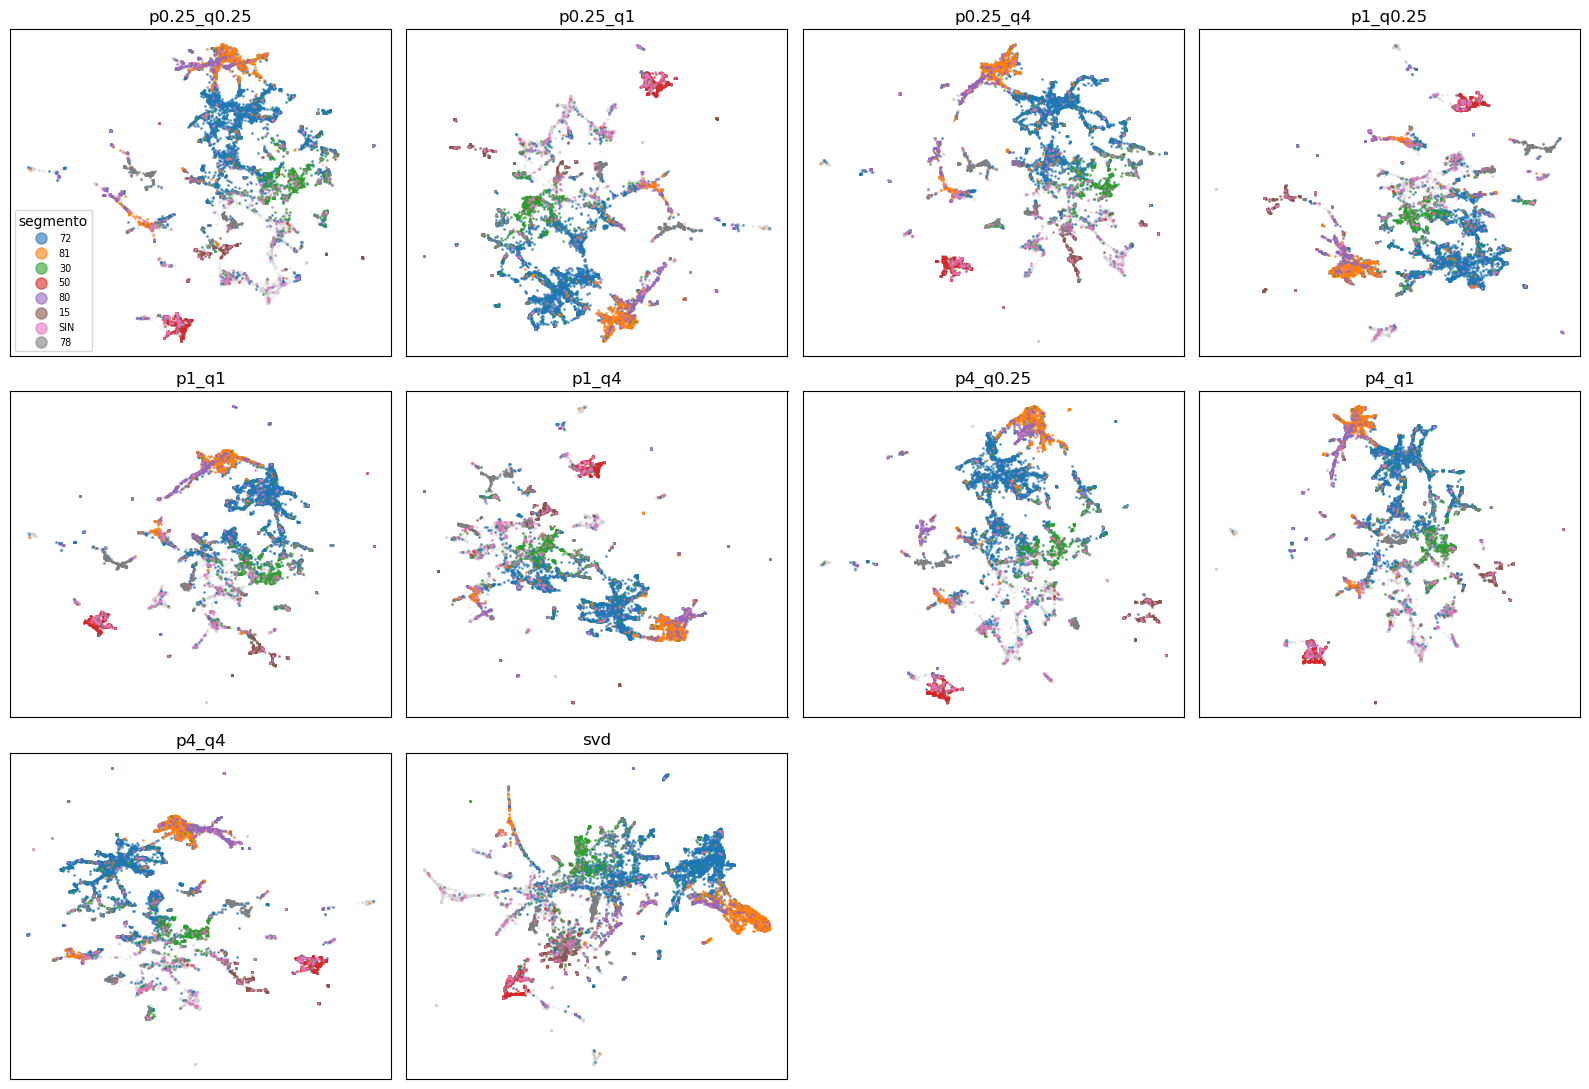

In [7]:
proy = {}
for c, E in embs.items():
    proy[c] = umap.UMAP(n_neighbors=VECINOS_UMAP, min_dist=MIN_DIST, metric="cosine", random_state=SEED).fit_transform(E[m_umap])
seg = nodos.segmento.iloc[m_umap].fillna("SIN").to_numpy()
top_seg = pd.Series(seg).value_counts().index[:8]
paleta = dict(zip(top_seg, plt.cm.tab10.colors))
def dibujar(ax, Y, etiqueta, cats, titulo):
    ax.scatter(Y[:, 0], Y[:, 1], s=1, c="lightgray", alpha=.3)
    for cat in cats:
        mk = etiqueta == cat
        ax.scatter(Y[mk, 0], Y[mk, 1], s=1, color=paleta.get(cat), alpha=.6, label=cat)
    ax.set(title=titulo, xticks=[], yticks=[])
confs_pq = [c for c in embs if c != "svd"]
fig, ax = plt.subplots(3, 4, figsize=(16, 11))
for a_, c in zip(ax.ravel(), confs_pq + ["svd"]):
    dibujar(a_, proy[c], seg, top_seg, c)
for a_ in ax.ravel()[len(embs):]:
    a_.axis("off")
ax[0, 0].legend(markerscale=8, fontsize=7, title="segmento", loc="lower left")
mostrar_fig("umap_grilla_segmento")

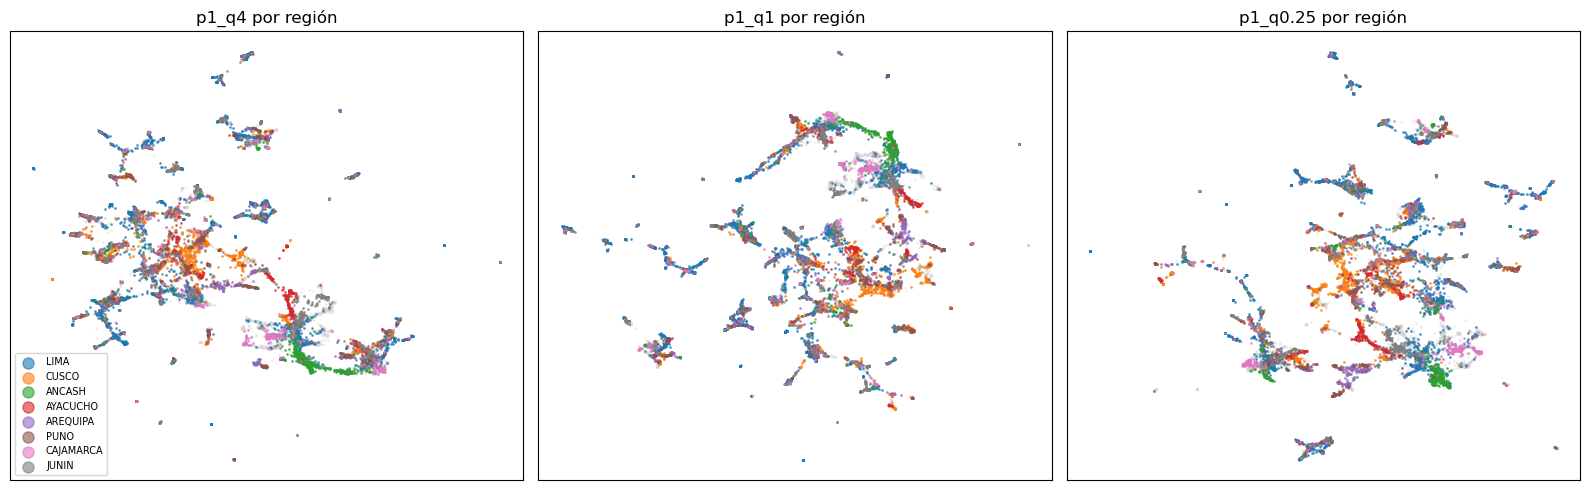

In [8]:
reg = nodos.region.iloc[m_umap].fillna("SIN").to_numpy()
top_reg = pd.Series(reg).value_counts().index[:8]
paleta = dict(zip(top_reg, plt.cm.tab10.colors))
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a_, c in zip(ax, ["p1_q4", "p1_q1", "p1_q0.25"]):
    dibujar(a_, proy[c], reg, top_reg, f"{c} por región")
ax[0].legend(markerscale=8, fontsize=7, loc="lower left")
mostrar_fig("umap_region")

- **Todas las configuraciones dibujan los mismos mercados**, solo rotados o reflejados (UMAP no conserva la orientación):

    - **Obras (72)** forman el bloque central más grande, con **consultoría de ingeniería (81, 80)** pegada a él: se licitan juntas (expediente, supervisión, ejecución)

    - **Alimentos (50)** es una isla separada en las 10 proyecciones: sus proveedores casi no co-participan con otros rubros

    - **Combustibles (15), materiales de construcción (30) y transporte (78)** forman grupos chicos en la periferia

- **Por región**, el bloque de obras se separa en zonas geográficas (Lima, Cusco, …): dentro de un rubro, la región ordena

- **SVD** también separa los rubros, pero con brazos largos y menos grupos compactos: no tiene la vecindad local de los paseos

---
### **3. Clustering latente**

- **KMeans** sobre los embeddings normalizados (distancia euclidiana entre vectores unitarios = coseno)

- *k* por silueta (sobre `N_SIL` puntos), igual que en `02_Clustering`

In [9]:
def kmeans_lat(E, k):
    return KMeans(n_clusters=k, n_init=4, random_state=SEED).fit_predict(E)

m_sil = rng.choice(n, N_SIL, replace=False)
etiquetas, silueta = {}, []
for c, E in embs.items():
    for k in RANGO_K:
        lab = kmeans_lat(E, k)
        etiquetas[(c, k)] = lab
        silueta.append({"config": c, "k": k, "silueta": silhouette_score(E[m_sil], lab[m_sil])})
silueta = pd.DataFrame(silueta)
tabla_sil = silueta.pivot(index="config", columns="k", values="silueta").round(3)
tabla_sil

k,4,6,8,10,12,15,20
config,,,,,,,
p0.25_q0.25,0.134,0.138,0.141,0.160,0.169,0.179,0.182
p0.25_q1,0.127,0.135,0.149,0.153,0.166,0.178,0.174
p0.25_q4,0.122,0.128,0.144,0.152,0.159,0.167,0.170
p1_q0.25,0.137,0.142,0.150,0.164,0.171,0.189,0.197
p1_q1,0.132,0.140,0.146,0.157,0.173,0.185,0.185
p1_q4,0.126,0.138,0.149,0.161,0.168,0.178,0.189
p4_q0.25,0.138,0.141,0.151,0.164,0.175,0.194,0.201
p4_q1,0.135,0.140,0.150,0.162,0.171,0.189,0.184
p4_q4,0.129,0.136,0.153,0.161,0.171,0.166,0.176


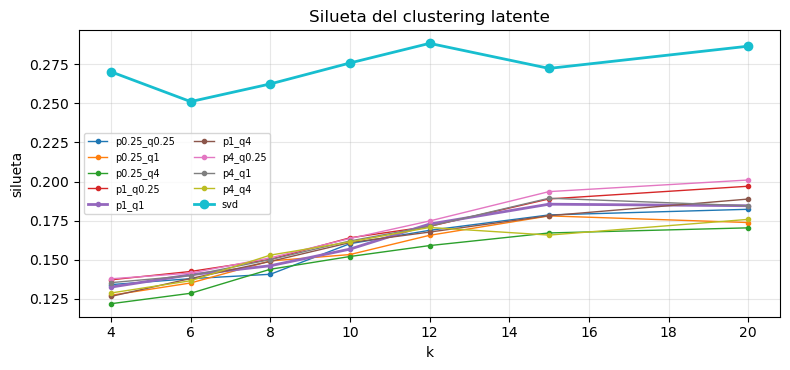

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for c, d in silueta.groupby("config"):
    ax.plot(d.k, d.silueta, "o-" if c == "svd" else ".-", label=c, lw=2 if c in ("p1_q1", "svd") else 1)
ax.set(xlabel="k", ylabel="silueta", title="Silueta del clustering latente"); ax.legend(fontsize=7, ncol=2)
mostrar_fig("silueta_latente")

#### a. Estabilidad y tamaño de los grupos

- **Estabilidad:** ARI entre dos ejecuciones de KMeans con semillas distintas (p = 1, q = 1)

- **% en el grupo mayor:** un *k* con un grupo gigante y el resto diminutos no describe mercados

In [11]:
estab_k = pd.DataFrame([{"k": k, "ari_semillas": adjusted_rand_score(etiquetas[("p1_q1", k)],
                                                                      KMeans(n_clusters=k, n_init=4, random_state=SEED + 1).fit_predict(embs["p1_q1"])),
                         **{f"% grupo mayor {c}": 100 * np.bincount(etiquetas[(c, k)]).max() / n for c in ("p1_q1", "svd")}}
                        for k in RANGO_K]).round(3)
estab_k

,k,ari_semillas,% grupo mayor p1_q1,% grupo mayor svd
0,4,0.990,30.945,42.413
1,6,0.987,20.795,28.390
2,8,0.777,20.439,26.889
3,10,0.745,17.567,28.097
4,12,0.731,13.653,28.105
5,15,0.795,13.511,15.600
6,20,0.701,9.550,15.939


- **La silueta es baja (0.13-0.20) y sube con *k*:** no hay un número "natural" de grupos; los mercados se tocan entre sí (proveedores multi-rubro y multi-región)

- **Estabilidad:** ARI entre semillas de **0.99 con k = 4 y 6**, y cae a 0.70-0.80 desde k = 8: con más grupos, KMeans corta el continuo de forma arbitraria

- Con k = 6 el grupo mayor tiene el 21% de los nodos (31% con k = 4)

- Se fija `K_LAT = 6`: el *k* más alto con partición estable

- **SVD:** silueta mayor (0.25-0.29) pero con un grupo que concentra 28-42% de los nodos

In [12]:
K_LAT = 6

---
### **4. Convergencia con las partes anteriores**

- Grupos latentes (`K_LAT`) contra cada partición previa, solo en los nodos que tienen ambas etiquetas

- **Descriptivas:** región y segmento modal (¿el embedding separa mercados geográficos o de rubro?)

- **Parte II:** tipologías de KMeans, DBSCAN, HDBSCAN y Ward (perfiles de comportamiento)

- **Parte V:** comunidades Louvain (partición principal)

In [13]:
refs = {"región": nodos.region.to_numpy(), "segmento": nodos.segmento.to_numpy(),
        "tipología (KMeans II)": nodos.tipologia.to_numpy()}
for c in ("dbscan", "hdbscan", "jerarquico"):
    if c in previas:
        refs[f"{c} (II)"] = previas[c].to_numpy()
if comunidades is not None:
    refs["comunidad (V)"] = comunidades
conv = pd.DataFrame([{"config": c, "referencia": r, **convergencia(etiquetas[(c, K_LAT)], v_)}
                     for c in embs for r, v_ in refs.items()])
conv_nmi = conv.pivot(index="config", columns="referencia", values="nmi").round(3)
conv_nmi

referencia,comunidad (V),dbscan (II),hdbscan (II),jerarquico (II),región,segmento,tipología (KMeans II)
config,,,,,,,
p0.25_q0.25,0.534,0.006,0.062,0.070,0.123,0.363,0.087
p0.25_q1,0.533,0.006,0.065,0.072,0.117,0.360,0.093
p0.25_q4,0.536,0.005,0.064,0.073,0.108,0.347,0.091
p1_q0.25,0.532,0.007,0.063,0.067,0.122,0.364,0.087
p1_q1,0.535,0.006,0.063,0.068,0.116,0.367,0.088
p1_q4,0.542,0.006,0.068,0.068,0.114,0.368,0.087
p4_q0.25,0.533,0.006,0.063,0.068,0.122,0.366,0.088
p4_q1,0.538,0.007,0.066,0.070,0.121,0.368,0.091
p4_q4,0.530,0.006,0.065,0.072,0.113,0.363,0.091


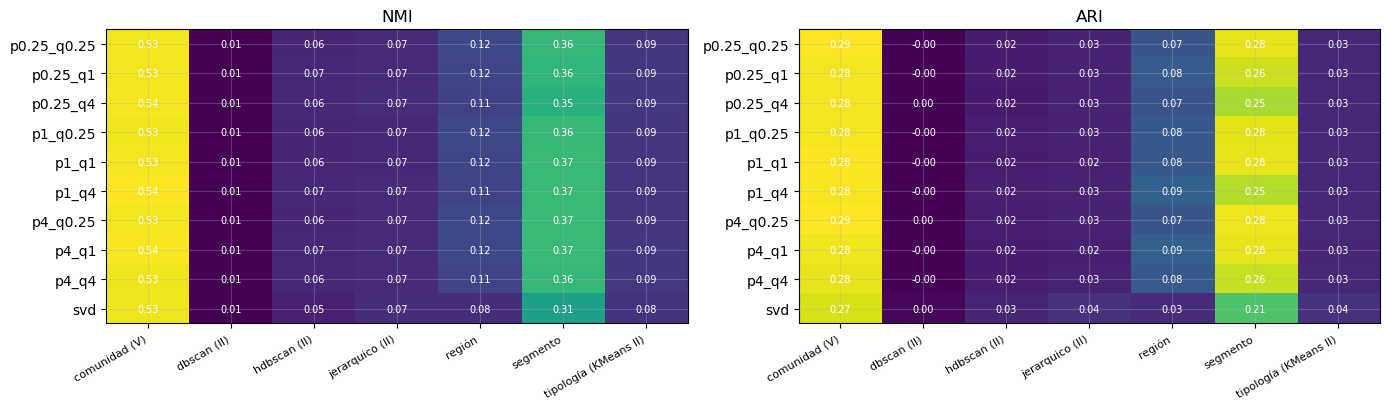

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a_, met in zip(ax, ["nmi", "ari"]):
    M = conv.pivot(index="config", columns="referencia", values=met)
    im = a_.imshow(M, cmap="viridis", aspect="auto")
    a_.set(xticks=range(M.shape[1]), xticklabels=M.columns, yticks=range(M.shape[0]), yticklabels=M.index, title=met.upper())
    plt.setp(a_.get_xticklabels(), rotation=30, ha="right", fontsize=8)
    for (r_, s_), val in np.ndenumerate(M.to_numpy()):
        a_.text(s_, r_, f"{val:.2f}", ha="center", va="center", color="w", fontsize=7)
mostrar_fig("convergencia")

In [15]:
if comunidades is None:
    print("Cruce con la Parte V: pendiente. Al existir el artefacto, esta tabla y la figura incluyen la columna 'comunidad (V)'")
else:
    m5 = pd.notna(comunidades)
    com5 = comunidades[m5].astype(str)
    k5 = len(set(com5))
    km5 = {c: KMeans(n_clusters=k5, n_init=4, random_state=SEED).fit_predict(embs[c]) for c in ("p1_q1", "p0.25_q4", "p4_q0.25", "svd")}
    cruce_v = pd.DataFrame([{"config": c, "k": k_, "nmi": normalized_mutual_info_score(com5, lab[m5]),
                             "ari": adjusted_rand_score(com5, lab[m5]),
                             "anidamiento": pureza(com5, lab[m5])}
                            for c in km5 for k_, lab in ((K_LAT, etiquetas[(c, K_LAT)]), (k5, km5[c]))])
    print(f"Parte V: {k5} comunidades (Louvain) en {m5.sum():,} nodos del núcleo | anidamiento = % de nodos en el grupo latente mayoritario de su comunidad")
    display(cruce_v.round(3))

Parte V: 41 comunidades (Louvain) en 7,116 nodos del núcleo | anidamiento = % de nodos en el grupo latente mayoritario de su comunidad


,config,k,nmi,ari,anidamiento
0,p1_q1,6,0.535,0.284,0.833
1,p1_q1,41,0.772,0.576,0.667
2,p0.25_q4,6,0.536,0.283,0.830
3,p0.25_q4,41,0.779,0.585,0.680
4,p4_q0.25,6,0.533,0.286,0.832
5,p4_q0.25,41,0.752,0.524,0.640
6,svd,6,0.531,0.268,0.851
7,svd,41,0.761,0.623,0.748


- **El embedding agrupa por rubro:** NMI de 0.36-0.37 con el segmento UNSPSC, contra 0.11-0.12 con la región

- **Converge poco con las tipologías de la Parte II** (NMI ≈ 0.09, ARI ≈ 0.03): miden cosas **distintas**

    - Parte II: **comportamiento** (tamaño, competencia, dependencia de un cliente), con features agregadas

    - Parte VI: **posición en el mercado** (con quién compite cada proveedor)

    - Un "típico de pocos clientes" puede estar en obras o en alimentos: las dos particiones son **complementarias**, no redundantes

- **DBSCAN:** NMI ≈ 0 y pureza 0.98 porque deja casi todo en un grupo; no hay nada que comparar

- **p y q casi no cambian la convergencia** (NMI segmento de 0.35 a 0.37): lo mismo que en `b_node2vec`

- **Parte V: la mayor convergencia de todas** (NMI 0.535 con k = 6), como se esperaba: ambos salen del mismo grafo

    - **Anidamiento 0.83:** las 41 comunidades caen casi enteras dentro de un mismo grupo latente; los 6 mercados del embedding son **agrupaciones de comunidades**

    - Con el mismo número de grupos (k = 41) el NMI sube a **0.75-0.78** y el ARI a 0.52-0.62: dos métodos distintos (Louvain sobre aristas, Node2Vec sobre paseos) recuperan casi la misma estructura

    - Diferencia: Louvain solo cubre el núcleo denso (7,116 nodos); el embedding ubica también a los 50 mil proveedores periféricos

#### a. Tipologías de la Parte II dentro de los grupos latentes

Configuración de referencia p = 1, q = 1: composición de cada grupo latente según la tipología de KMeans (solo proveedores con tipología)

In [16]:
CONF_REF = "p1_q1"
lat = etiquetas[(CONF_REF, K_LAT)]
cruce_tip = pd.crosstab(lat[nodos.tipologia.notna()], nodos.tipologia.dropna(), normalize="index").round(3)
cruce_tip.index.name = "grupo latente"
cruce_tip

tipologia,contratistas de obras,ganadores sin competencia,grandes multicliente,típicos de pocos clientes
grupo latente,,,,
0,0.041,0.048,0.191,0.720
1,0.005,0.020,0.337,0.638
2,0.445,0.055,0.023,0.477
3,0.048,0.037,0.120,0.795
4,0.016,0.012,0.150,0.822
5,0.063,0.047,0.253,0.637


- **El grupo 2 (obras civiles) concentra a los "contratistas de obras":** 44% de sus proveedores con tipología, contra 0-6% en los demás

- Es la única tipología de la Parte II que coincide con un grupo latente: es la única definida por **rubro** (`pct_obras`)

- **"Grandes multicliente"** se reparte en todos los grupos (12-34%): hay proveedores grandes en cada mercado

- **"Típicos de pocos clientes"** es mayoría en todos (48-82%): es la tipología más común

---
### **5. Centralidad (Parte IV) en el espacio latente**

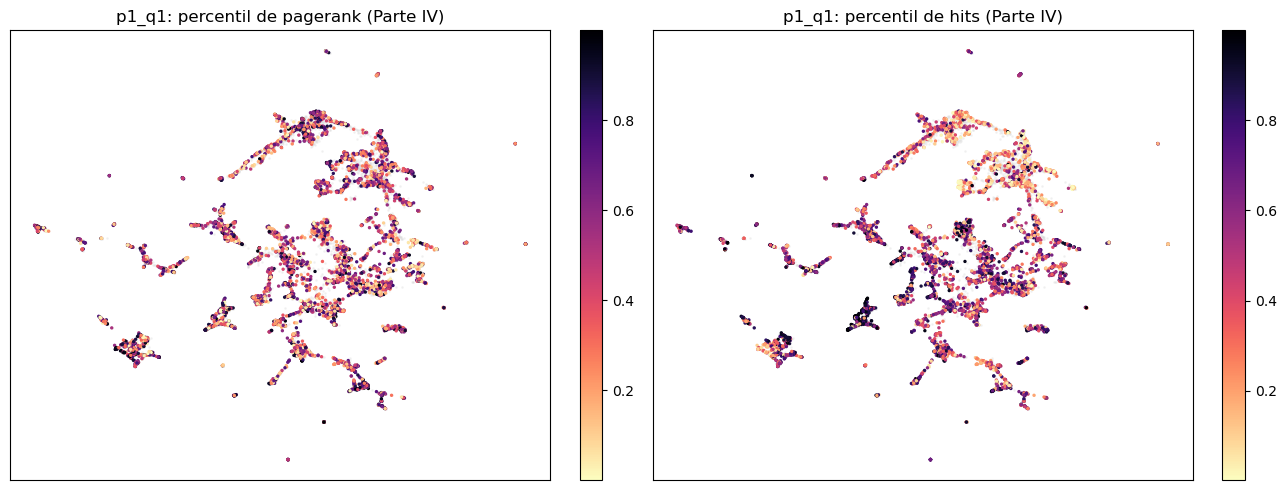

In [17]:
if nodos.pct_pagerank.notna().any():
    i_c = np.flatnonzero(nodos.pct_pagerank.iloc[m_umap].notna().to_numpy())
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    for a_, col in zip(ax, ["pct_pagerank", "pct_hits"]):
        a_.scatter(proy[CONF_REF][:, 0], proy[CONF_REF][:, 1], s=1, c="lightgray", alpha=.2)
        sc = a_.scatter(proy[CONF_REF][i_c, 0], proy[CONF_REF][i_c, 1], s=2, c=nodos[col].iloc[m_umap].to_numpy()[i_c], cmap="magma_r")
        a_.set(title=f"{CONF_REF}: percentil de {col[4:]} (Parte IV)", xticks=[], yticks=[])
        plt.colorbar(sc, ax=a_, fraction=.046)
    mostrar_fig("umap_centralidad")

- **PageRank se reparte en todo el mapa:** cada mercado tiene sus proveedores centrales; la centralidad no es exclusiva de un rubro

- **HITS se concentra en islas densas**: el núcleo de compras que la Parte IV identificó (sobre todo salud)

- **Embedding y centralidad son ortogonales:** el embedding dice **dónde** compite un proveedor; PageRank y HITS, **cuánto pesa** ahí

---
### **6. Perfil de los grupos latentes**

In [18]:
def moda_pct(s):
    vc = s.dropna().value_counts(normalize=True)
    return f"{vc.index[0]} ({100 * vc.iloc[0]:.0f}%)" if len(vc) else "—"

d_ = nodos.assign(grupo=lat, gano=(nodos.n_ganados > 0).astype(int))
perfiles = d_.groupby("grupo").agg(
    proveedores=("idx", "size"), region=("region", moda_pct), segmento=("segmento", moda_pct),
    familia=("familia", moda_pct), pct_gano=("gano", "mean"), procesos_mediana=("n_procesos", "median"),
    regiones_mediana=("n_regiones", "median"), pct_con_tipologia=("tipologia", lambda s: s.notna().mean()),
    tipologia=("tipologia", moda_pct), pagerank_pct_medio=("pct_pagerank", "mean"))
perfiles["ejemplos"] = d_.sort_values("grado", ascending=False).groupby("grupo").nombre.apply(lambda s: " | ".join(s.head(3)))
perfiles.round(3)

,proveedores,region,segmento,familia,pct_gano,procesos_mediana,regiones_mediana,pct_con_tipologia,tipologia,pagerank_pct_medio,ejemplos
grupo,,,,,,,,,,,
0,7325,LIMA (33%),50 (27%),1510 (21%),0.568,7.0,1.0,0.306,típicos de pocos clientes (72%),0.550,CARTER & HURTADO S.R.L. | POMAJUICA GOMEZ YULIANA SABRINA | GRUPO MC Y GH S....
1,10398,LIMA (45%),42 (11%),5310 (8%),0.537,11.0,3.0,0.272,típicos de pocos clientes (64%),0.507,GRUPO HEICI S.A.C | ROMAC SOLUTIONS E.I.R.L. | SUDAMERICANA LOGISTICA HISUKI...
2,11848,LIMA (20%),72 (96%),7214 (61%),0.337,16.0,2.0,0.122,típicos de pocos clientes (48%),0.512,RRW SERVICIOS GENERALES E.I.R.L | MAYOLDA INVERSIONES S.A.C. | EL HORIZONTE ...
3,6774,LIMA (22%),81 (64%),8110 (63%),0.330,11.0,3.0,0.119,típicos de pocos clientes (79%),0.504,ANGULAR INGENIEROS S.A.C. | ZARZOSA PRUDENCIO JORGE ARTURO | MEGARCON CONTRA...
4,11029,CUSCO (32%),72 (43%),7214 (27%),0.488,13.0,2.0,0.213,típicos de pocos clientes (82%),0.459,GRUPO CORPORATIVO 3NAV S.A.C. | INVESTMENTS GLOBO S.A.C. | HACHT CONSULTORES...
5,9601,LIMA (64%),72 (24%),7215 (13%),0.451,10.0,2.0,0.208,típicos de pocos clientes (64%),0.481,PROFESIONALES ASOCIADOS EN SERVICIOS DE CALIDAD QNC-PASEC QNC S.A.C. | J.H.P...


| Grupo | Mercado | Rasgos |
|---|---|---|
| 0 | **Alimentos y combustibles** (50, 15) | Lima 33%; 57% ganó alguna vez; mediana de 1 región |
| 1 | **Bienes diversos en Lima y Callao** (equipo médico 42, laboratorio 41, vestimenta 53) | 45% Lima |
| 2 | **Obras civiles** (96% segmento 72) | Lima, Áncash, Cajamarca, La Libertad; solo 34% ganó: mucha oferta, pocos ganadores |
| 3 | **Consultoría de ingeniería** (64% familia 8110) | Lima y Áncash; 33% ganó |
| 4 | **Sur andino** (Cusco 32%, Puno, Ayacucho, Apurímac) | Obras (43%) + materiales de construcción (31%) |
| 5 | **Servicios y construcción especializada en Lima** (64% Lima) | Servicios de construcción (7215), consultoría |

- **PQ2 (mercados):** emergen **por rubro**, y dentro del rubro **por región**; el sur andino es el único grupo definido sobre todo por geografía

- **Obras y consultoría** son los mercados con más postores por adjudicación ganada (34% y 33% ganó): mucha competencia o mucha oferta de baja probabilidad

- El centro de PageRank es parecido en los 6 grupos (percentil medio 0.46-0.55)

---
### **7. Escritura de datos**

- `temp/datos/latente_<config>.parquet`: idx y etiqueta para cada *k* de `RANGO_K` (todos los nodos)

- `temp/datos/umap_<config>.parquet`: coordenadas 2D de los `N_UMAP` nodos proyectados

In [19]:
for c in embs:
    pd.DataFrame({"idx": np.arange(n), **{f"k{k}": etiquetas[(c, k)] for k in RANGO_K}}).to_parquet(datos_dir / f"latente_{c}.parquet", index=False)
    pd.DataFrame({"idx": m_umap, "x": proy[c][:, 0], "y": proy[c][:, 1]}).to_parquet(datos_dir / f"umap_{c}.parquet", index=False)
config.update({"vecinos_umap": VECINOS_UMAP, "k_lat": K_LAT, "conf_ref": CONF_REF, "rango_k": RANGO_K})
guardar_config(config)

#### a. Verificación

In [20]:
for c in embs:
    l_, u_ = pd.read_parquet(datos_dir / f"latente_{c}.parquet"), pd.read_parquet(datos_dir / f"umap_{c}.parquet")
    assert len(l_) == n and len(u_) == N_UMAP and u_[["x", "y"]].notna().all().all(), c
print(f"OK: {len(embs)} configuraciones con etiquetas latentes y proyección")

OK: 10 configuraciones con etiquetas latentes y proyección


---
### **8. Escritura de resultados**

- `umap_web`: `N_WEB` nodos × configuración, con x, y y el grupo latente para cada *k* (la web cambia p, q y k sin recalcular)

- `nodos_web`: atributos de esos nodos para colorear y filtrar

In [21]:
m_web = np.sort(rng.choice(N_UMAP, N_WEB, replace=False))
idx_web = m_umap[m_web]
umap_web = pd.concat([pd.DataFrame({"config": c, "idx": idx_web, "x": proy[c][m_web, 0].round(3), "y": proy[c][m_web, 1].round(3),
                                    **{f"k{k}": etiquetas[(c, k)][idx_web] for k in RANGO_K}}) for c in embs], ignore_index=True)
cols_web = ["idx", "nombre", "region", "segmento", "familia", "tipologia", "grado", "n_procesos", "n_ganados",
            "pct_pagerank", "pct_hits"]
nodos_web = nodos.iloc[idx_web][cols_web].fillna({"tipologia": "sin tipología", "segmento": "SIN", "familia": "SIN"})
escritos = guardar_tablas({**({"cruce_v": cruce_v} if comunidades is not None else {}), "cobertura": cobertura, "umap_parametros": umap_param, "silueta": silueta,
                           "convergencia": conv, "cruce_tipologia": cruce_tip.reset_index(),
                           "perfiles_latentes": perfiles.reset_index(), "estabilidad_k": estab_k, "umap_web": umap_web, "nodos_web": nodos_web})

Escrito en 06_Embeddings/temp/c_proyeccion/: cruce_v, cobertura, umap_parametros, silueta, convergencia, cruce_tipologia, perfiles_latentes, estabilidad_k, umap_web, nodos_web


#### a. Verificación

In [22]:
verificar_salidas(escritos)

OK: 10 tablas (parquet + json) | 5 figuras: convergencia, silueta_latente, umap_centralidad, umap_grilla_segmento, umap_region


---
### **9. Cerrar sesión**

In [23]:
spark.stop()